# ANÁLISE DE MERCADO PARA ABERTURA DE UMA CAFETERIA COM GARÇONS ROBÔS EM LOS ANGELES

## Introdução

Este projeto tem como objetivo analisar o mercado de estabelecimentos alimentícios em Los Angeles, identificando suas principais características e tendências, a fim de avaliar a viabilidade da abertura de uma cafeteria com garçons robôs e fornecer informações relevantes para potenciais investidores.

## Descrição dos dados 

### rest_data: '/datasets/rest_data_us_upd.csv.'
* object_name — nome de estabelecimento
* chain — estabelecimento de rede (TRUE/FALSE)
* object_type — tipo de estabelecimento
* address — endereço
* number — número de assentos

### Apresentação
Presentation: https://drive.google.com/file/d/1b9FA1X0vlhnECHz4aIJ_J2-jjwC2Jw7z/view?usp=sharing



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
#analisando o data 
rest_data = pd.read_csv('/datasets/rest_data_us_upd.csv')
rest_data.head(10)

,id,object_name,address,chain,object_type,number
0,11786,HABITAT COFFEE SHOP,3708 N EAGLE ROCK BLVD,False,Cafe,26
1,11787,REILLY'S,100 WORLD WAY 120,False,Restaurant,9
2,11788,STREET CHURROS,6801 HOLLYWOOD BLVD 253,False,Fast Food,20
3,11789,TRINITI ECHO PARK,1814 W SUNSET BLVD,False,Restaurant,22
4,11790,POLLEN,2100 ECHO PARK AVE,False,Restaurant,20
5,11791,THE SPOT GRILL,10004 NATIONAL BLVD,False,Restaurant,14
6,11792,CPK,100 WORLD WAY 126,False,Restaurant,100
7,11793,PHO LALA,3500 W 6TH ST STE 226,False,Restaurant,7
8,11794,ABC DONUTS,3027 N SAN FERNANDO RD UNIT 103,True,Fast Food,1
9,11795,UPSTAIRS,3707 N CAHUENGA BLVD,False,Restaurant,35


In [3]:
#analisando as informações e as colunas do data 
rest_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9651 entries, 0 to 9650
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           9651 non-null   int64 
 1   object_name  9651 non-null   object
 2   address      9651 non-null   object
 3   chain        9648 non-null   object
 4   object_type  9651 non-null   object
 5   number       9651 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 452.5+ KB


In [4]:
#vendo se tem valores ausentes na coluna chain 
rest_data['chain'].value_counts(dropna=False)

False    5972
True     3676
NaN         3
Name: chain, dtype: int64

In [5]:
rest_data[rest_data['chain'].isna()]

,id,object_name,address,chain,object_type,number
7408,19194,TAQUERIA LOS 3 CARNALES,5000 E WHITTIER BLVD,NaN,Restaurant,14
7523,19309,JAMMIN JIMMY'S PIZZA,1641 FIRESTONE BLVD,NaN,Pizza,1
8648,20434,THE LEXINGTON THEATER,129 E 3RD ST,NaN,Restaurant,35


In [6]:
#convertendo a coluna Chain para boleano 
rest_data['chain'] = rest_data['chain'].astype('boolean')

In [7]:
#verificando os valores ausentes e duplicados 
print(rest_data.isna().sum())
print(rest_data.duplicated().sum())

id             0
object_name    0
address        0
chain          3
object_type    0
number         0
dtype: int64
0



### Conclusão da Limpeza de Dados

Durante a análise inicial, foram identificados três valores ausentes (`NaN`) na coluna `chain`. As demais colunas não apresentaram valores ausentes.

A coluna `chain`, originalmente do tipo `object`, foi convertida para o tipo booleano, pois indica se o estabelecimento pertence ou não a uma rede.

Optei por manter os três valores ausentes, evitando classificações incorretas dos estabelecimentos. Esses registros serão considerados durante a análise, conforme a necessidade de cada investigação.

# Proporções dos tipos de estabelecimentos

In [8]:
#numeros de estabelecimentos por tipo
proporcoes = rest_data['object_type'].value_counts(normalize=True) * 100
proporcoes

Restaurant    75.173557
Fast Food     11.045488
Cafe           4.507305
Pizza          3.315719
Bar            3.025593
Bakery         2.932339
Name: object_type, dtype: float64

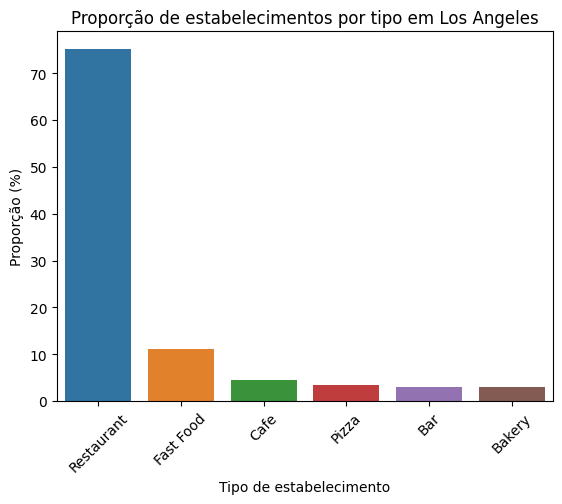

In [9]:
#gráfico de proporções plt.figure(figsize=(10, 5))

sns.barplot(
    x=proporcoes.index,
    y=proporcoes.values
)

plt.title('Proporção de estabelecimentos por tipo em Los Angeles')
plt.xlabel('Tipo de estabelecimento')
plt.ylabel('Proporção (%)')
plt.xticks(rotation=45)
plt.show()




# CONCLUSÃO GRÁFICO DE PROPORÇÃO DE TIPOS DE ESTABELECIMENTOS 


A análise demonstrou que os restaurantes tradicionais representam a maior proporção de estabelecimentos em Los Angeles, com 75,17%, seguidos pelos estabelecimentos de fast food, com 11,05%.

Essa diferença mostra uma predominância significativa dos restaurantes tradicionais na composição do mercado analisado.

Uma possível explicação para essa distribuição está relacionada aos hábitos de consumo da população. Entretanto, seriam necessários dados adicionais sobre o comportamento dos consumidores para confirmar essa hipótese.

# Proporções de estabelecimentos de redes e locais.

In [10]:
#proporções de estabelecimentos 
proporcao_redes = rest_data['chain'].value_counts(normalize=True) * 100

print(proporcao_redes)

False    61.898839
True     38.101161
Name: chain, dtype: Float64


In [11]:
#agrupando por tipo e categoria 
rest_data.groupby(['object_type', 'chain']).size()
#calculando as proporções por tipo 
proporcao_por_tipo = (
    rest_data.groupby('object_type')['chain']
    .value_counts(normalize=True)
    .mul(100)
    .unstack()
)

print(proporcao_por_tipo)

chain            False       True 
object_type                       
Bakery             NaN  100.000000
Bar          73.630137   26.369863
Cafe         38.850575   61.149425
Fast Food    43.245779   56.754221
Pizza        52.037618   47.962382
Restaurant   68.399283   31.600717


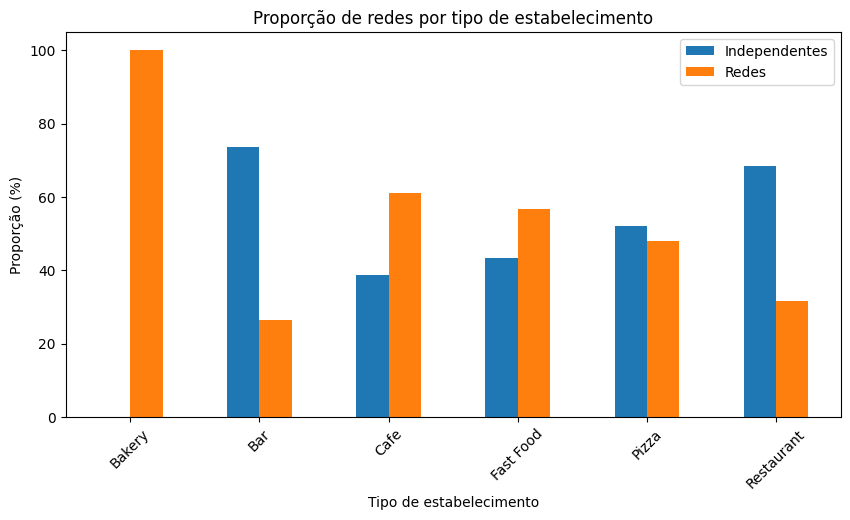

Restaurant    7255
Fast Food     1066
Cafe           435
Pizza          320
Bar            292
Bakery         283
Name: object_type, dtype: int64


In [12]:
ax = proporcao_por_tipo.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Proporção de redes por tipo de estabelecimento')
plt.xlabel('Tipo de estabelecimento')
plt.ylabel('Proporção (%)')
plt.xticks(rotation=45)
plt.legend(['Independentes', 'Redes'])
plt.show()

#quantidades de cada estabelecimetno em los angeles
print(rest_data['object_type'].value_counts())

### Conclusão — Proporção de Redes por Tipo de Estabelecimento

A análise demonstra que a presença de redes varia conforme o tipo de estabelecimento em Los Angeles.

As padarias apresentam 100% de estabelecimentos pertencentes a redes na amostra analisada. As cafeterias também possuem predominância de redes, com 61,15%, seguidas pelos estabelecimentos de fast food, com 56,75%.

Em contrapartida, os bares e restaurantes apresentam predominância de estabelecimentos independentes, com 73,63% e 68,40%, respectivamente. As pizzarias apresentam uma distribuição mais equilibrada entre os dois modelos.

Esses resultados sugerem que as redes possuem maior participação em algumas categorias associadas a refeições rápidas e consumo cotidiano. Entretanto, não podemos concluir que isso represente diretamente a preferência dos consumidores, pois não temos dados sobre seus hábitos de consumo.

Para nosso projeto, a presença de redes em 61,15% das cafeterias indica que esse formato de negócio é frequente no segmento analisado, tornando relevante investigar suas características operacionais e possibilidades de expansão.

# Analisando qual tipo de estabelecimento é típico para redes 


In [13]:
#filtrar apenas o estabelecimentos que pertencem a rede
estabelecimentos_rede = rest_data[rest_data['chain'] == True]
#contar o total dos estabelecimentos que tem nesse tipo 
tipos_rede = estabelecimentos_rede['object_type'].value_counts()

print(tipos_rede)

Restaurant    2292
Fast Food      605
Bakery         283
Cafe           266
Pizza          153
Bar             77
Name: object_type, dtype: int64


In [14]:
#calculando a participação por categoria 
proporcao_tipos_rede = (
    estabelecimentos_rede['object_type']
    .value_counts(normalize=True) * 100
)
print(proporcao_tipos_rede)

Restaurant    62.350381
Fast Food     16.458107
Bakery         7.698585
Cafe           7.236126
Pizza          4.162133
Bar            2.094668
Name: object_type, dtype: float64


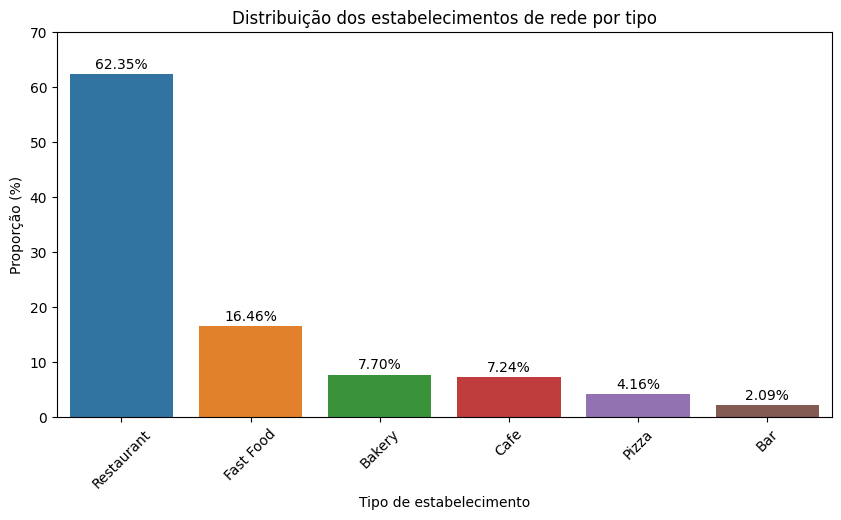

In [15]:
# Proporção de cada tipo entre os estabelecimentos de rede
proporcao_tipos_rede = (
    rest_data.loc[rest_data['chain'] == True, 'object_type']
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=proporcao_tipos_rede.index,
    y=proporcao_tipos_rede.values
)

# Porcentagens acima das barras
for i, valor in enumerate(proporcao_tipos_rede.values):
    ax.text(i, valor + 1, f'{valor:.2f}%', ha='center')

plt.title('Distribuição dos estabelecimentos de rede por tipo')
plt.xlabel('Tipo de estabelecimento')
plt.ylabel('Proporção (%)')
plt.xticks(rotation=45)
plt.ylim(0, 70)
plt.show()

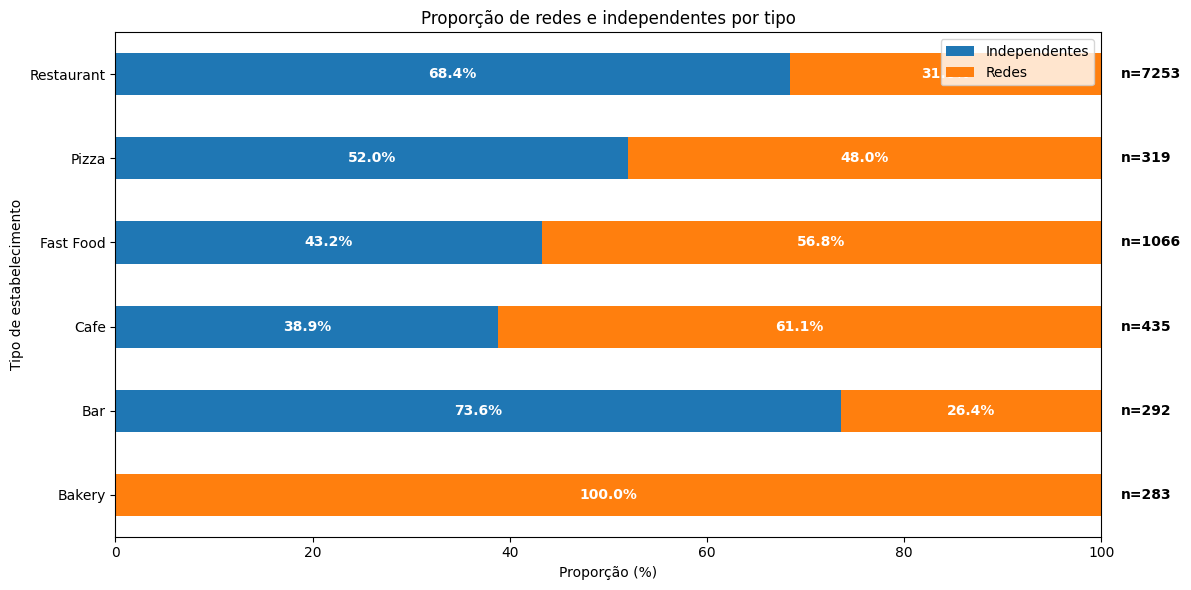

In [16]:
totais = rest_data.groupby('object_type')['chain'].count()
ax = proporcao_por_tipo.fillna(0).plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6)
)
# Porcentagens dentro das barras e total de estabelecimentos
for i, tipo in enumerate(proporcao_por_tipo.index):
    independente = proporcao_por_tipo.loc[tipo, False]
    rede = proporcao_por_tipo.loc[tipo, True]

    independente = 0 if pd.isna(independente) else independente
    rede = 0 if pd.isna(rede) else rede

    if independente > 0:
        ax.text(independente / 2, i, f'{independente:.1f}%',
                ha='center', va='center', color='white', fontweight='bold')

    if rede > 0:
        ax.text(independente + rede / 2, i, f'{rede:.1f}%',
                ha='center', va='center', color='white', fontweight='bold')

    ax.text(102, i, f'n={totais[tipo]}',
            va='center', fontweight='bold')
plt.title('Proporção de redes e independentes por tipo')
plt.xlabel('Proporção (%)')
plt.ylabel('Tipo de estabelecimento')
plt.xlim(0, 100)
plt.legend(['Independentes', 'Redes'])
plt.tight_layout()
plt.show()

### Conclusão — Análise de Redes e Estabelecimentos Independentes

Apesar de os restaurantes representarem a maior quantidade de estabelecimentos em Los Angeles, a maioria deles é independente, com 68,4%, enquanto 31,6% pertencem a redes.

As cafeterias apresentam um comportamento diferente: 61,1% pertencem a redes e 38,9% são independentes. Embora representem uma parcela menor do mercado, possuem a segunda maior proporção de estabelecimentos de rede dentro da própria categoria, ficando atrás apenas das padarias, que apresentam 100% de estabelecimentos classificados como redes na amostra.

Por outro lado, os bares apresentam predominância de estabelecimentos independentes, com 73,6%, enquanto apenas 26,4% pertencem a redes.

Esses resultados demonstram que a participação das redes varia conforme o tipo de estabelecimento. No caso das cafeterias, a predominância de redes é uma informação relevante para investigar a possibilidade de expansão do nosso modelo de negócio.

Entretanto, a presença de redes não garante a lucratividade ou o sucesso de uma nova cafeteria.


# O que caracteriza um estabelecimento independente de uma rede: 
* ## Muitos estabelecimentos com um poucos acentos ou poucos estabelecimentos com muitos assentos ?

In [17]:
#filtrando os estabelecimentos de rede
redes = rest_data[rest_data['chain'] == True]


caracteristicas_redes = redes.groupby('object_name').agg(
    quantidade_unidades=('number', 'size'),
    assentos_por_unidade=('number', 'mean')
)

print(caracteristicas_redes.head(10))

                          quantidade_unidades  assentos_por_unidade
object_name                                                        
#1 CHINESE FAST FOOD                        1                   6.0
1810 RESTAURANT                             1                  45.0
333                                         1                 180.0
3RD ST MARKET & DELI                        1                   7.0
4 CAMINOS RESTAURANT                        1                  18.0
5 LINE RESTAURANT                           1                  41.0
5684 YORK RESTAURANT                        1                 115.0
85 C BAKERY CAFE                            1                  45.0
85 CELSIUS BAKERY CAFE                      1                  37.0
A MI JAPANESE RESTAURANT                    1                 204.0


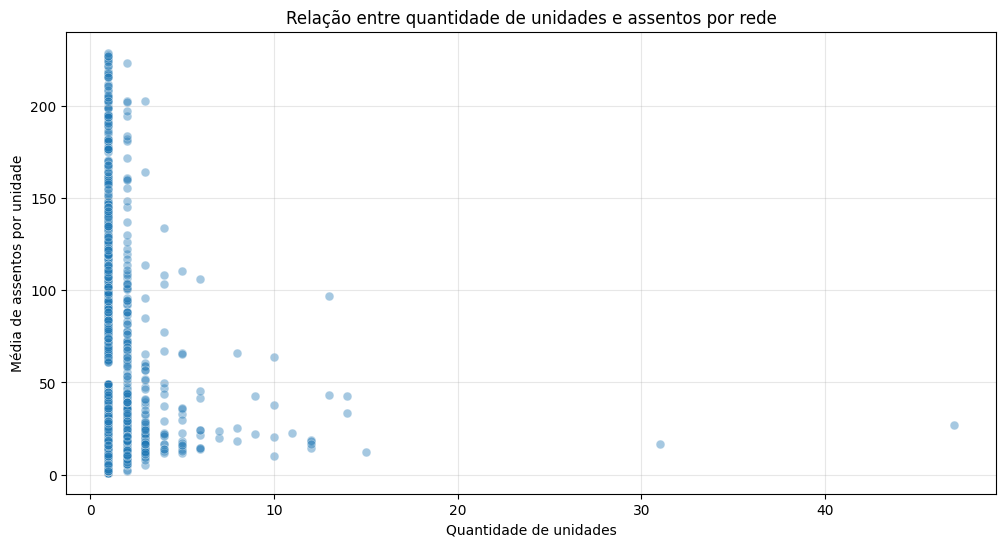

In [18]:
#gráfico de dispersão entre assentos de redes 

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=caracteristicas_redes,
    x='quantidade_unidades',
    y='assentos_por_unidade',
    alpha=0.4,
    s=40
)

plt.title('Relação entre quantidade de unidades e assentos por rede')
plt.xlabel('Quantidade de unidades')
plt.ylabel('Média de assentos por unidade')
plt.grid(alpha=0.3)
plt.show()

In [22]:

# Contar quantos nomes de redes possuem cada quantidade de unidades
distribuicao_unidades = (
    caracteristicas_redes['quantidade_unidades']
    .value_counts()
    .sort_index()
)

print(distribuicao_unidades)

1     2240
2      353
3       73
4       20
5       15
6        9
7        2
8        3
9        2
10       4
11       1
12       4
13       2
14       2
15       1
31       1
47       1
Name: quantidade_unidades, dtype: int64


In [23]:

# Criar faixas de quantidade de unidades
faixas = pd.cut(
    caracteristicas_redes['quantidade_unidades'],
    bins=[0, 1, 2, 5, 10, float('inf')],
    labels=['1 unidade', '2 unidades', '3 a 5', '6 a 10', 'Mais de 10']
)

distribuicao_faixas = faixas.value_counts().sort_index()

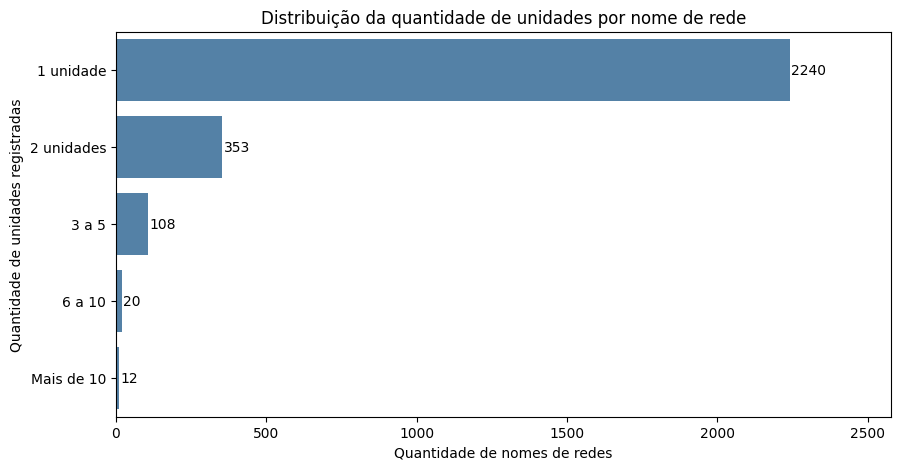

In [24]:
#gráfico da quantidade de unidades por nome de rede
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=distribuicao_faixas.values,
    y=distribuicao_faixas.index,
    color='steelblue'
)

# Valores ao lado das barras
for i, valor in enumerate(distribuicao_faixas.values):
    ax.text(valor + 5, i, str(valor), va='center')

plt.title('Distribuição da quantidade de unidades por nome de rede')
plt.xlabel('Quantidade de nomes de redes')
plt.ylabel('Quantidade de unidades registradas')
plt.xlim(0, distribuicao_faixas.max() * 1.15)

plt.show()

In [25]:
#descobrindo a mediana de assentos por unidade 
caracteristicas_redes['faixa_unidades'] = pd.cut(
    caracteristicas_redes['quantidade_unidades'],
    bins=[0, 1, 2, 5, 10, float('inf')],
    labels=['1 unidade', '2 unidades', '3 a 5', '6 a 10', 'Mais de 10']
)

caracteristicas_redes.groupby('faixa_unidades')[
    'assentos_por_unidade'
].median()

faixa_unidades
1 unidade     26.000000
2 unidades    24.000000
3 a 5         21.875000
6 a 10        23.714286
Mais de 10    20.564394
Name: assentos_por_unidade, dtype: float64

### Conclusão — Características dos Estabelecimentos de Rede

A análise demonstrou que a maioria dos nomes de estabelecimentos classificados como redes aparece com poucas unidades registradas no conjunto de dados.

Ao relacionar a quantidade de unidades com o número de assentos, observamos que os nomes com apenas uma unidade apresentam mediana de 26 assentos, enquanto aqueles com mais de dez unidades apresentam mediana de aproximadamente 20,56 assentos.

Esse resultado sugere que redes com maior número de unidades registradas tendem a operar estabelecimentos relativamente menores, embora essa relação não seja uniforme entre todas as faixas analisadas.

É importante considerar que a análise utiliza os nomes dos estabelecimentos como aproximação para identificar redes, não sendo possível determinar a quantidade total de unidades de cada empresa fora da amostra.

Para o projeto da cafeteria com garçons robôs, esse padrão pode contribuir para a investigação de modelos de expansão com unidades menores, mas ainda não permite estabelecer o tamanho ideal ou a viabilidade financeira do negócio.

# Descobrindo o número médio de assentos para cada tipo de restaurante. Em média, qual tipo de restaurante tem o maior número de assentos.

In [27]:
#calculando o numero médio de assentos por categoria
media_assentos = (
    rest_data.groupby('object_type')['number']
    .mean()
    .sort_values(ascending=False)
)

print(media_assentos)

object_type
Restaurant    48.042316
Bar           44.767123
Fast Food     31.837711
Pizza         28.459375
Cafe          25.000000
Bakery        21.773852
Name: number, dtype: float64


In [28]:
assentos_por_tipo = (
    rest_data.groupby('object_type')['number']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .sort_values('mean', ascending=False)
)

print(assentos_por_tipo)

             count       mean  median  min  max
object_type                                    
Restaurant    7255  48.042316    29.0    1  229
Bar            292  44.767123    28.5    1  227
Fast Food     1066  31.837711    21.0    1  227
Pizza          320  28.459375    18.5    1  216
Cafe           435  25.000000    21.0    1  143
Bakery         283  21.773852    18.0    1  218


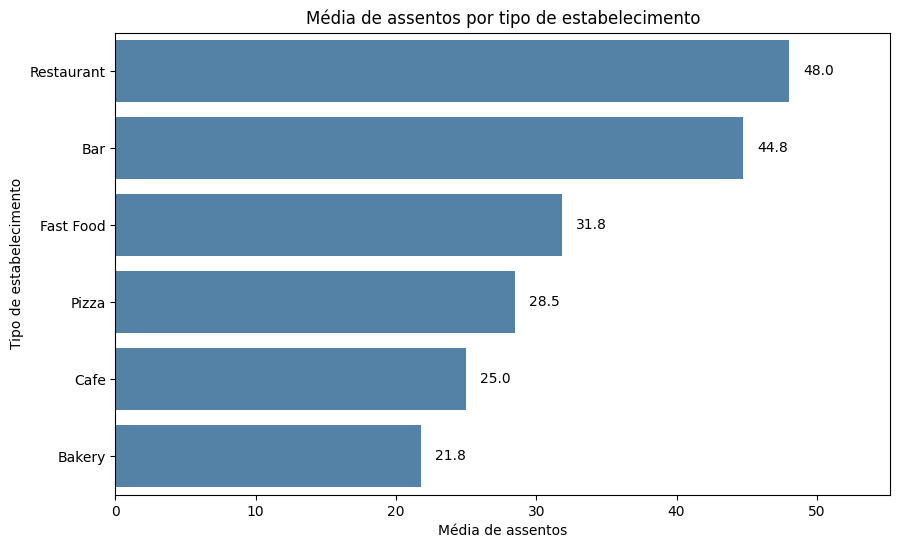

In [30]:
#média de assentos por tipo de segmento
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=assentos_por_tipo['mean'].values,
    y=assentos_por_tipo.index,
    color='steelblue'
)

# Valores ao lado das barras
for i, valor in enumerate(assentos_por_tipo['mean']):
    ax.text(valor + 1, i, f'{valor:.1f}', va='center')

plt.title('Média de assentos por tipo de estabelecimento')
plt.xlabel('Média de assentos')
plt.ylabel('Tipo de estabelecimento')
plt.xlim(0, assentos_por_tipo['mean'].max() * 1.15)

plt.show()

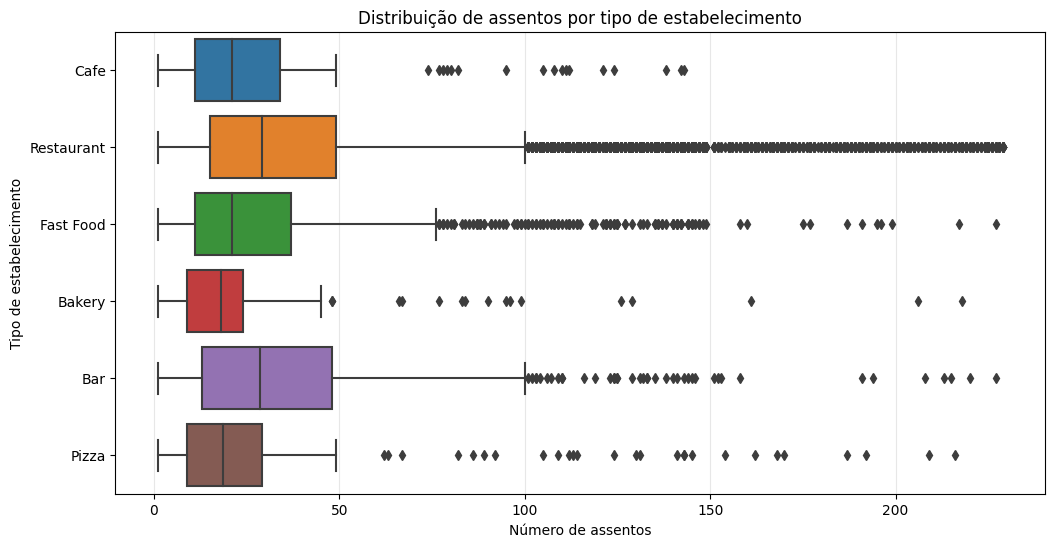

In [32]:
#grafico boxplot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=rest_data,
    x='number',
    y='object_type'
)

plt.title('Distribuição de assentos por tipo de estabelecimento')
plt.xlabel('Número de assentos')
plt.ylabel('Tipo de estabelecimento')
plt.grid(axis='x', alpha=0.3)
plt.show()

### Conclusão — Média e Distribuição de Assentos por Tipo de Estabelecimento

A análise mostrou que os restaurantes possuem a maior média de assentos (48), seguidos pelos bares (44,8). Já as cafeterias (25) e padarias (21,8) apresentam capacidades médias menores.

Ao observar o boxplot, identificamos uma maior dispersão nos restaurantes e bares, além de diversos valores extremos, que podem influenciar suas médias. Por outro lado, cafeterias e padarias apresentam uma distribuição mais concentrada em quantidades menores de assentos.

Essas diferenças podem estar relacionadas às necessidades operacionais de cada segmento, embora os dados não permitam confirmar o comportamento dos consumidores.

Para nosso projeto, a média de 25 assentos das cafeterias serve como referência inicial, mas ainda precisamos considerar o espaço necessário para os garçons robôs e a viabilidade operacional do estabelecimento.

# Separando os nomes das ruas na coluna adress para uma coluna separada 

In [34]:
#removendo o numero inicial e mantendo o nome completo da rua 
rest_data['street'] = (
    rest_data['address']
    .str.replace(r'^\s*\d+\s+', '', regex=True)
    .str.strip()
)
rest_data[['address', 'street']].head(10)

,address,street
0,3708 N EAGLE ROCK BLVD,N EAGLE ROCK BLVD
1,100 WORLD WAY 120,WORLD WAY 120
2,6801 HOLLYWOOD BLVD 253,HOLLYWOOD BLVD 253
3,1814 W SUNSET BLVD,W SUNSET BLVD
4,2100 ECHO PARK AVE,ECHO PARK AVE
5,10004 NATIONAL BLVD,NATIONAL BLVD
6,100 WORLD WAY 126,WORLD WAY 126
7,3500 W 6TH ST STE 226,W 6TH ST STE 226
8,3027 N SAN FERNANDO RD UNIT 103,N SAN FERNANDO RD UNIT 103
9,3707 N CAHUENGA BLVD,N CAHUENGA BLVD


In [35]:
#contanto os estabelecimentos por cada rua 
top_10_ruas = (
    rest_data['street']
    .value_counts()
    .head(10)
)

print(top_10_ruas)

W SUNSET BLVD        296
W PICO BLVD          288
HOLLYWOOD BLVD       167
WILSHIRE BLVD        161
S VERMONT AVE        148
SANTA MONICA BLVD    146
W 3RD ST             145
BEVERLY BLVD         135
S FIGUEROA ST        134
MELROSE AVE          128
Name: street, dtype: int64


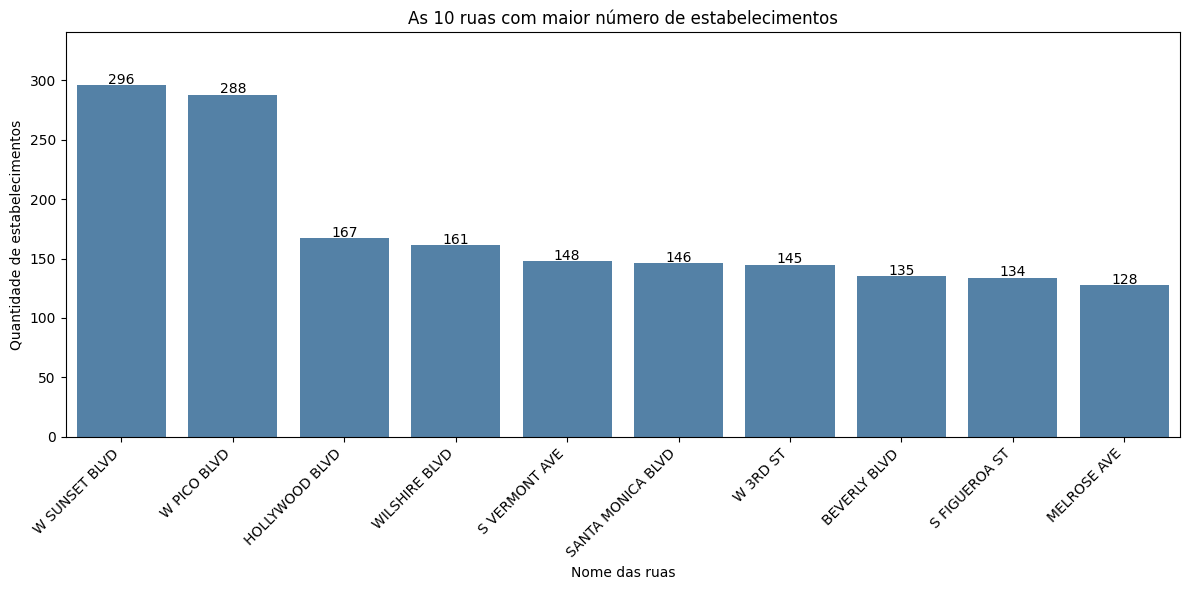

In [38]:
#construindo um gráfico das top10 ruas com mais restaurantes
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=top_10_ruas.index,
    y=top_10_ruas.values,
    color='steelblue'
)
# Adicionar valores acima das barras
for i, valor in enumerate(top_10_ruas.values):
    ax.text(i, valor + 1, str(valor), ha='center')

plt.title('As 10 ruas com maior número de estabelecimentos')
plt.xlabel('Nome das ruas')
plt.ylabel('Quantidade de estabelecimentos')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, top_10_ruas.max() * 1.15)

plt.tight_layout()
plt.show()

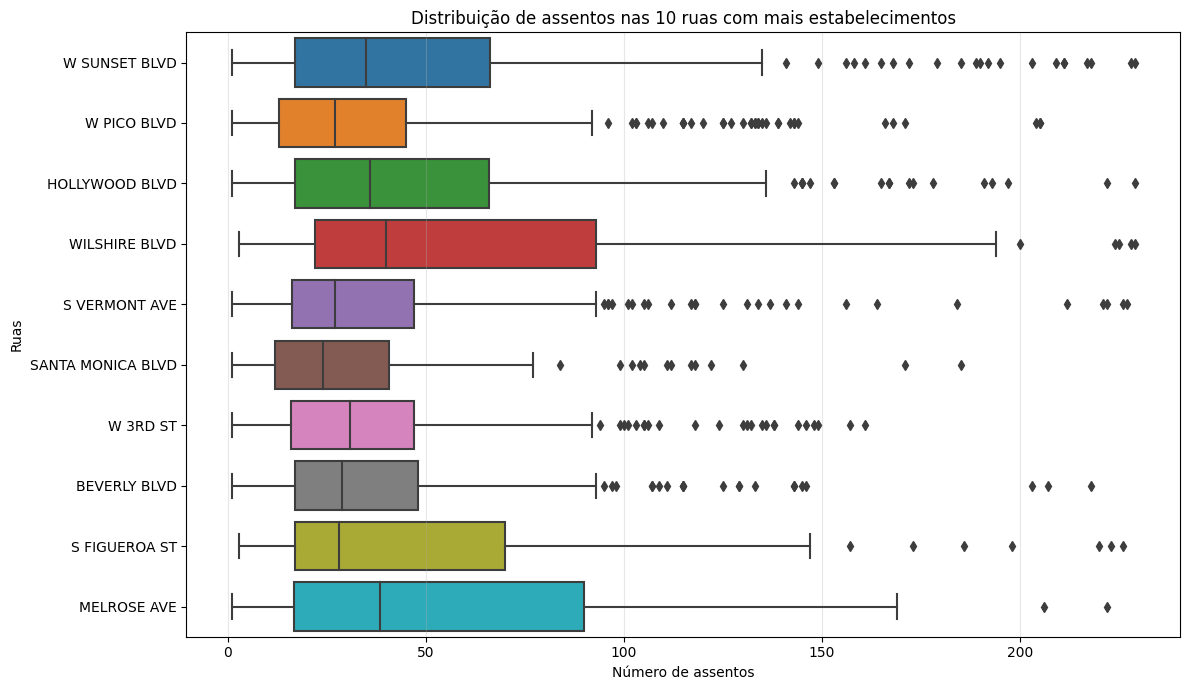

In [45]:
# Identificar as 10 ruas com mais estabelecimentos
top_10_ruas = rest_data['street'].value_counts().head(10).index
# Filtrar os estabelecimentos das 10 ruas com mais estabelecimentos
dados_top_ruas = rest_data[
    rest_data['street'].isin(top_10_ruas)
]

plt.figure(figsize=(12, 7))
sns.boxplot(
    data=dados_top_ruas,
    x='number',
    y='street',
    order=top_10_ruas
)

plt.title('Distribuição de assentos nas 10 ruas com mais estabelecimentos')
plt.xlabel('Número de assentos')
plt.ylabel('Ruas')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


In [48]:
#encontrando o numero de ruas
restaurantes_por_rua = rest_data['street'].value_counts()

ruas_com_um = (restaurantes_por_rua == 1).sum()

print(ruas_com_um)

2450


### Conclusão — Concentração de Estabelecimentos e Distribuição de Assentos

A análise mostrou que W Sunset Blvd (296) e W Pico Blvd (288) possuem as maiores concentrações de estabelecimentos. Em contrapartida, identificamos **2.450 ruas com apenas um estabelecimento registrado**, demonstrando que também existe uma distribuição de estabelecimentos por diversas ruas da cidade.

Ao analisar o boxplot, observamos que as ruas com maior concentração de estabelecimentos não apresentam necessariamente as maiores capacidades de assentos. Wilshire Blvd, por exemplo, possui 161 estabelecimentos e apresenta uma das maiores medianas, além de grande variação na quantidade de assentos.

De modo geral, os resultados mostram diferentes padrões de concentração e capacidade dos estabelecimentos. Para nossa futura cafeteria, essas informações ajudam a identificar possíveis regiões para investigação, mas ainda precisamos considerar a concorrência, a demanda e os custos antes de definir uma localização.

## Conclusão Geral e Recomendações

**A análise indica que uma cafeteria de pequeno porte, com aproximadamente 25 assentos, é uma opção coerente com o mercado estudado.** Essa capacidade corresponde à média observada nas cafeterias de Los Angeles e deve ser ajustada às necessidades de circulação dos garçons robôs.

O segmento também apresenta potencial para investigar a expansão em rede, já que **61,15% das cafeterias analisadas pertencem a redes**. Entretanto, essa predominância não garante rentabilidade nem sucesso comercial.

**Minha recomendação é iniciar com uma única unidade piloto**, priorizando uma localização com demanda comprovada e custos operacionais viáveis. As ruas W Sunset Blvd e W Pico Blvd merecem investigação por concentrarem muitos estabelecimentos, mas essa concentração também pode representar concorrência elevada.

O principal risco é que a tecnologia atraia clientes inicialmente, sem garantir sua fidelização. Por isso, antes de expandir, será necessário avaliar faturamento, lucratividade, retorno dos clientes e custos de manutenção dos robôs.

**A expansão para uma rede só deve ocorrer quando a primeira unidade demonstrar capacidade de gerar resultados financeiros sustentáveis, independentemente do interesse inicial pela novidade.**

Presentation: <https://drive.google.com/file/d/1b9FA1X0vlhnECHz4aIJ_J2-jjwC2Jw7z/view?usp=sharing>